# NB06: Spatiotemporal Scale Topology Walkthrough

This notebook covers RELIC's multi-scale simulation framework. You will learn:

1. Spatial scale labels (`SpatialScale`) and their runtime preference rank
2. Temporal grouping: fast, medium and slow execution groups (priority chain and parameter-database thresholds)
3. Operator splitting (Lie and Strang) within the fast group, and multi-rate sequencing between groups
4. How `scale_ops.py` and `execution_loop.py` implement the theory
5. The Functor-level `VariableKind` role labels (STATE, FLUX, DIAGNOSTIC, PARAMETER, FORCING, UNKNOWN)

**Prerequisites:** NB01-NB05.

**Theory Reference:** `docs/source/theory/spatiotemporal_scale_topology.md`.

## Architecture Anchor

This notebook is aligned with `docs\source\architecture_overview.md` and the relevant theory/API pages under `docs\source`.
All computations below are intended to use actual RELIC functors, the actual simulator or orchestration layer, and real validation pathways rather than notebook-defined pseudo-process equations.


### Spatiotemporal Scale Topology

RELIC supports multi-scale simulation via the **scale coupling** framework.
Each Functor declares one `spatial_scale` label, for example

$$
\texttt{POINT},\ \texttt{PATCH},\ \texttt{GRID\_CELL},\ \texttt{HILLSLOPE},\ \texttt{BASIN},\ \texttt{LANDSCAPE},\ \texttt{REGIONAL},\ \texttt{GLOBAL}
$$

The intended reading is finer to coarser; the runtime only ranks these labels (Part 2) and stores no geometry.

**Fast/Medium/Slow grouping** assigns each Functor to one execution group by one priority chain in which
the first declared rule decides: the `register_functor(execution_group=...)` argument, the Functor
attribute `execution_group`, `characteristic_time_days`, `temporal_scale` metadata, the config entry
`process_groups[name]` (used only when none of the rules before it applies), and `fast` only
when nothing is declared. Every declaration is validated, also when a higher rule decides: an invalid
group name, a `characteristic_time_days` that is not a finite non-negative number, an unrecognized
`temporal_scale`, or a `process_groups` entry that contradicts the attribute, characteristic-time or
temporal-scale rule raises `ValueError` (the `register_functor` argument overrides the entry).

- **Fast group**: runs every step (e.g. photosynthesis, stomatal dynamics)
- **Medium group**: runs when a `medium_interval_seconds` boundary is crossed or a medium event trigger fires
- **Slow group**: runs at `slow_interval_seconds` boundaries if that key is set, otherwise at calendar-month
  boundaries of the configured calendar (`noleap` or `360_day`), or when a slow event trigger fires
  (e.g. soil decomposition, phenology)

Within the fast group, `splitting_mode` selects **Lie** (sequential) or **Strang**
(palindromic) composition of that group's Functors $F_1,\dots,F_n$. Medium and slow
groups are not part of this composition; they run sequentially at their own cadence:

$$
\Phi_{\Delta t}^{\text{Lie}} = \Phi_{F_n}^{\Delta t} \circ \cdots \circ \Phi_{F_1}^{\Delta t}
\qquad
\Phi_{\Delta t}^{\text{Strang}}
= \Phi_{F_1}^{\Delta t/2} \circ \cdots \circ \Phi_{F_{n-1}}^{\Delta t/2}
  \circ \Phi_{F_n}^{\Delta t}
  \circ \Phi_{F_{n-1}}^{\Delta t/2} \circ \cdots \circ \Phi_{F_1}^{\Delta t/2}
$$

## Setup and Imports

Import the scale topology utilities and the core RELIC modules.

In [1]:
from __future__ import annotations

# Event loop compatibility patch (required for nbconvert/Jupyter execution)
import asyncio
if hasattr(asyncio, "WindowsSelectorEventLoopPolicy"):
    asyncio.set_event_loop_policy(asyncio.WindowsSelectorEventLoopPolicy())

# --- Environment Guard (prevent OpenMP duplicate lib crash) ---
import os, sys
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import json
import sys
from pathlib import Path
from types import SimpleNamespace

DEFAULT_PROJECT_ROOT = Path(os.environ.get("RELIC_PROJECT_ROOT", Path.cwd())).resolve()

def locate_project_root() -> Path:
    candidates = [
        Path.cwd(),
        Path.cwd().parent,
        Path.cwd().parent.parent,
        DEFAULT_PROJECT_ROOT,
    ]
    for candidate in candidates:
        candidate = candidate.resolve()
        if (candidate / "relic").exists() and (candidate / "tutorial").exists():
            return candidate
    raise RuntimeError("Project root not found from current working directory")

PROJECT_ROOT = locate_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from relic.core.functor.functor_types import SpatialScale, TemporalScale, VariableKind
from relic.core.simulator.time_ops import compute_interval_index, should_execute_medium, should_execute_slow
from relic.coupling.scales.execution_plan import (
    LevelSpec,
    RegridSpec,
    build_execution_plan,
    build_manifest,
    validate_topology,
    write_manifest,
)

OUTPUT_DIR = PROJECT_ROOT / "tutorial" / "primary" / "output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MANIFEST_PATH = OUTPUT_DIR / "spatiotemporal_scale_topology_manifest.yaml"

print("[OK] project_root =", PROJECT_ROOT)
print("[OK] output_dir =", OUTPUT_DIR)
print("[OK] manifest_path =", MANIFEST_PATH)


[OK] project_root = <RELIC_ROOT>
[OK] output_dir = tutorial\primary\output
[OK] manifest_path = tutorial\primary\output\spatiotemporal_scale_topology_manifest.yaml


## Spatial Scale Hierarchy

Inspect the `SpatialScale` labels, the calendar-dependent period of `TemporalScale.MONTH`, and the
`VariableKind` role labels. The spatial labels are only ranked (Part 2); moving data between levels
needs explicit scale operators and grid descriptors.

In [2]:
# References:
# - docs/source/theory/spatiotemporal_scale_topology.md, Section 1.1, Section 1.2, and Section 1.3.
# - relic/core/functor/functor_types.py.
# Mathematical expression:
# - tau(day) = 1 day; tau(week) = Delta_week; tau(month) = b_1 - b_0 from calendar bounds.
# - The spatial scale order is interpreted as a finer-to-coarser hierarchy in the theory document.
# Parameter meanings:
# - tau(t): characteristic process time in days.
# - spatial_scale: Functor-level spatial label (no geometry).
# - variable_kind: Functor-level role label (state, flux, diagnostic, parameter, forcing, unknown).
# Units: all realized periods and returned characteristic times are in days.
# Domain/constraints: week/month durations must be explicit, finite, and positive; month is calendar-dependent.
# Sign convention: elapsed durations are positive.

import torch
from relic.coupling.scales.temporal.calendar import CalendarHandler

spatial_scales = [
    SpatialScale.POINT,
    SpatialScale.PATCH,
    SpatialScale.GRID_CELL,
    SpatialScale.HILLSLOPE,
    SpatialScale.BASIN,
    SpatialScale.GLOBAL,
]

selected_temporal_scales = [TemporalScale.DAY, TemporalScale.WEEK, TemporalScale.MONTH]
calendar = CalendarHandler(calendar_type="noleap", time_units="days since 2001-01-01")
january_bounds = calendar.create_time_bounds(
    torch.tensor([14.0], dtype=torch.float64),
    frequency="monthly",
    method="centered",
)
january_days = float((january_bounds[0, 1] - january_bounds[0, 0]).item())
realized_period_days = {
    TemporalScale.DAY: 1.0,
    TemporalScale.WEEK: 7.0,
    TemporalScale.MONTH: january_days,
}
temporal_scale_days = {
    scale.value: scale.to_characteristic_time_days(period_days=realized_period_days[scale])
    for scale in selected_temporal_scales
}

variable_kind_values = [kind.value for kind in VariableKind]

assert temporal_scale_days["day"] == 1.0
assert temporal_scale_days["week"] == 7.0
assert temporal_scale_days["month"] == 31.0
assert "state" in variable_kind_values
assert "flux" in variable_kind_values

scale_semantics_summary = {
    "spatial_scales": [scale.value for scale in spatial_scales],
    "temporal_scale_days": temporal_scale_days,
    "variable_kind_values": variable_kind_values,
}

scale_semantics_summary

{'spatial_scales': ['point',
  'patch',
  'grid_cell',
  'hillslope',
  'basin',
  'global'],
 'temporal_scale_days': {'day': 1.0, 'week': 7.0, 'month': 31.0},
 'variable_kind_values': ['state',
  'flux',
  'diagnostic',
  'parameter',
  'forcing',
  'unknown']}

## Temporal Scale Separation

Inspect the multi-level scale plan. Group assignment itself (fast/medium/slow) follows the priority chain above - the `register_functor` argument, Functor attribute, `characteristic_time_days`, `TemporalScale` metadata, `process_groups`, and `fast` only when nothing is declared - and is exercised in the band cell below and in Part 2.

In [3]:
# References:
# - docs/source/theory/spatiotemporal_scale_topology.md, Section 2.1 and Section 2.2.
# - relic/coupling/scales/execution_plan.py.
# Mathematical expression:
# - A regrid edge defines a morphism source -> target in the scale topology.
# - time_ratio = Delta_t_target / Delta_t_source for hierarchical aggregation steps.
# Parameter meanings:
# - LevelSpec.time_step: characteristic coupling time step in seconds for one scale level.
# - RegridSpec.time_ratio: integer ratio between source and target execution intervals.
# - manifest.hash: stable digest of the topology payload.

levels = [
    LevelSpec(name="patch", time_step=1800.0, spatial_resolution="patch"),
    LevelSpec(name="grid_cell", time_step=86400.0, spatial_resolution="grid_cell"),
    LevelSpec(name="basin", time_step=604800.0, spatial_resolution="basin"),
]

regrids = [
    RegridSpec(source="patch", target="grid_cell", method="hierarchical", time_ratio=48),
    RegridSpec(source="grid_cell", target="basin", method="hierarchical", time_ratio=7),
]

validate_topology(levels, regrids)
steps = build_execution_plan(levels, regrids)
manifest = build_manifest(levels, regrids, steps)
write_manifest(MANIFEST_PATH, manifest)

assert manifest["levels"][0]["name"] == "patch"
assert manifest["regrids"][0]["time_ratio"] == 48
assert len(manifest["steps"]) == 2
assert len(manifest["hash"]) == 12

plan_summary = {
    "level_names": [level.name for level in levels],
    "level_time_steps_seconds": {level.name: level.time_step for level in levels},
    "regrid_edges": [f"{spec.source}->{spec.target}" for spec in regrids],
    "step_count": len(steps),
    "manifest_hash": manifest["hash"],
    "manifest_path": str(MANIFEST_PATH),
}

plan_summary

{'level_names': ['patch', 'grid_cell', 'basin'],
 'level_time_steps_seconds': {'patch': 1800.0,
  'grid_cell': 86400.0,
  'basin': 604800.0},
 'regrid_edges': ['patch->grid_cell', 'grid_cell->basin'],
 'step_count': 2,
 'manifest_hash': 'c42cd2b66957',
 'manifest_path': './workspace'}

## Execution Bands and Interval Predicates

The execution-group thresholds live in the parameter database and are read by
`resolve_scheduling_thresholds()`. The band cell below classifies realized periods through the
runtime `determine_execution_group()` (characteristic-time branch); the thresholds classify Functors,
they are not execution intervals. Probing an interval predicate does not consume a trigger.
NB12 runs the Lie and Strang compositions of the fast group.

In [4]:
# References:
# - docs/source/theory/spatiotemporal_scale_topology.md, Section 1.2 and Section 1.3.
# - relic/core/simulator/dependency_ops.py (resolve_scheduling_thresholds, determine_execution_group).
# - relic/parameters/database/relic/computation/scheduling.yaml.
# Mathematical expression:
# - gamma(t) = fast if tau(t) <= tau_f.
# - gamma(t) = medium if tau_f < tau(t) <= tau_m.
# - gamma(t) = slow if tau(t) > tau_m.
# Parameter meanings:
# - tau(t): characteristic process time in days.
# - tau_f, tau_m: computation.scheduling.fast/medium_group_max_characteristic_days from the parameter database.
# - gamma(t): group returned by the runtime characteristic-time branch of determine_execution_group().
# Units: tau, tau_f, tau_m and period_days are in days; gamma is categorical.
# Domain/constraints: 0 < tau_f < tau_m is enforced by the resolver; calendar-dependent scales need a realized duration.
# Sign convention: elapsed durations are positive.

from relic.core.simulator.dependency_ops import determine_execution_group, resolve_scheduling_thresholds

FAST_MAX_DAYS, MEDIUM_MAX_DAYS = resolve_scheduling_thresholds()
# determine_execution_group() reads and validates config process_groups for every Functor; an
# entry decides only when no earlier rule applies, and it must agree with the attribute,
# characteristic-time or temporal-scale rule when one of them decides.
# This stand-in exposes the simulator settings accessor with an empty configuration.
NO_PROCESS_GROUPS = SimpleNamespace(_get_setting=lambda key, default: default)


def runtime_band(scale: TemporalScale, period_days: float) -> str:
    # A probe Functor that declares characteristic_time_days = tau(scale) and nothing else.
    tau_days = scale.to_characteristic_time_days(period_days=period_days)
    probe = SimpleNamespace(name=f"{scale.value}_band_probe", characteristic_time_days=tau_days)
    return determine_execution_group(NO_PROCESS_GROUPS, probe)


temporal_band_summary = {
    "fast_max_days": FAST_MAX_DAYS,
    "medium_max_days": MEDIUM_MAX_DAYS,
    "day_band": runtime_band(TemporalScale.DAY, realized_period_days[TemporalScale.DAY]),
    "week_band": runtime_band(TemporalScale.WEEK, realized_period_days[TemporalScale.WEEK]),
    "month_band": runtime_band(TemporalScale.MONTH, realized_period_days[TemporalScale.MONTH]),
}

assert 0.0 < FAST_MAX_DAYS < MEDIUM_MAX_DAYS
assert temporal_band_summary["day_band"] == "fast"
assert temporal_band_summary["week_band"] == "medium"
assert temporal_band_summary["month_band"] == "slow"

temporal_band_summary

{'fast_max_days': 1.0,
 'medium_max_days': 10.0,
 'day_band': 'fast',
 'week_band': 'medium',
 'month_band': 'slow'}

## Interval Predicates and Commit

A medium group fires when $\lfloor t/T_m \rfloor$ exceeds its committed index; the slow group uses
$\lfloor t/T_s \rfloor$ when `slow_interval_seconds` is set and otherwise the calendar-month index of
the configured calendar (`noleap` or `360_day`, see Part 2). Only `commit_rate_group_interval()`
advances a committed index, after the group ran inside an accepted step.

`VariableKind` (listed in the first code cell) is a separate, Functor-level role label: STATE, FLUX,
DIAGNOSTIC, PARAMETER, FORCING, UNKNOWN. There is no INCREMENT kind; the update mode comes from each
returned `UpdateItem`.

In [5]:
# References:
# - docs/source/theory/spatiotemporal_scale_topology.md, Section 5.1 and Section 5.2.
# - relic/core/simulator/time_ops.py (should_execute_medium/slow, commit_rate_group_interval).
# Mathematical expression:
# - index = floor(t / T_interval)
# - A group fires when the current interval index exceeds the committed index;
#   the committed index advances only through commit_rate_group_interval.
# Parameter meanings:
# - t: simulation time in seconds.
# - T_interval: group execution interval in seconds.
# - previous_index: last committed interval index for a temporal group.
# Units: t and T_interval in seconds; indices are dimensionless integers.
# Domain/constraints: the predicates are pure, so probing them never consumes a trigger.
# Sign convention: committed indices are monotone non-decreasing.

from relic.core.simulator.time_ops import commit_rate_group_interval

interval_index_example = compute_interval_index(90000.0, 86400.0)

medium_probe = SimpleNamespace(
    current_time=0.0,
    _medium_interval_seconds=86400.0,
    _previous_medium_index=-1,
    _previous_day_index=-1,
)
# Pure predicate: two probes at the same time agree and leave the tracker untouched.
assert should_execute_medium(medium_probe, 0.0) is True
assert should_execute_medium(medium_probe, 0.0) is True
assert medium_probe._previous_medium_index == -1

medium_sequence = []
for probe_time in (0.0, 3600.0, 86400.0):
    fires = should_execute_medium(medium_probe, probe_time)
    medium_sequence.append(fires)
    if fires:
        commit_rate_group_interval(medium_probe, "medium", probe_time)

# slow_interval_seconds is set, so the calendar-month path is not used by this probe.
slow_probe = SimpleNamespace(
    current_time=0.0,
    _slow_interval_seconds=604800.0,
    _previous_slow_index=-1,
    _previous_month_index=-1,
)
slow_sequence = []
for probe_time in (0.0, 86400.0, 604800.0):
    fires = should_execute_slow(slow_probe, probe_time)
    slow_sequence.append(fires)
    if fires:
        commit_rate_group_interval(slow_probe, "slow", probe_time)

assert interval_index_example == 1
assert medium_sequence == [True, False, True]
assert slow_sequence == [True, False, True]
assert medium_probe._previous_medium_index == 1
assert slow_probe._previous_slow_index == 1

time_summary = {
    "interval_index_example": interval_index_example,
    "medium_sequence": medium_sequence,
    "slow_sequence": slow_sequence,
    "committed_medium_index": medium_probe._previous_medium_index,
    "committed_slow_index": slow_probe._previous_slow_index,
}

time_summary

{'interval_index_example': 1,
 'medium_sequence': [True, False, True],
 'slow_sequence': [True, False, True],
 'committed_medium_index': 1,
 'committed_slow_index': 1}

In [6]:
summary = {
    "scale_semantics_summary": scale_semantics_summary,
    "plan_summary": plan_summary,
    "temporal_band_summary": temporal_band_summary,
    "time_summary": time_summary,
}

output_path = OUTPUT_DIR / "spatiotemporal_scale_topology_summary.json"
output_path.write_text(json.dumps(summary, indent=2, ensure_ascii=True), encoding="utf-8")

print("[OK] wrote", output_path)
print("[OK] wrote", MANIFEST_PATH)
print("[OK] manifest_hash =", summary["plan_summary"]["manifest_hash"])
print("[OK] day_band =", summary["temporal_band_summary"]["day_band"])
print("[OK] week_band =", summary["temporal_band_summary"]["week_band"])
print("[OK] month_band =", summary["temporal_band_summary"]["month_band"])
print("[OK] interval_index_example =", summary["time_summary"]["interval_index_example"])
print("[OK] medium_sequence =", summary["time_summary"]["medium_sequence"])
print("[OK] slow_sequence =", summary["time_summary"]["slow_sequence"])

summary

[OK] wrote tutorial\primary\output\spatiotemporal_scale_topology_summary.json
[OK] wrote tutorial\primary\output\spatiotemporal_scale_topology_manifest.yaml
[OK] manifest_hash = c42cd2b66957
[OK] day_band = fast
[OK] week_band = medium
[OK] month_band = slow
[OK] interval_index_example = 1
[OK] medium_sequence = [True, False, True]
[OK] slow_sequence = [True, False, True]


{'scale_semantics_summary': {'spatial_scales': ['point',
   'patch',
   'grid_cell',
   'hillslope',
   'basin',
   'global'],
  'temporal_scale_days': {'day': 1.0, 'week': 7.0, 'month': 31.0},
  'variable_kind_values': ['state',
   'flux',
   'diagnostic',
   'parameter',
   'forcing',
   'unknown']},
 'plan_summary': {'level_names': ['patch', 'grid_cell', 'basin'],
  'level_time_steps_seconds': {'patch': 1800.0,
   'grid_cell': 86400.0,
   'basin': 604800.0},
  'regrid_edges': ['patch->grid_cell', 'grid_cell->basin'],
  'step_count': 2,
  'manifest_hash': 'c42cd2b66957',
  'manifest_path': './workspace'},
 'temporal_band_summary': {'fast_max_days': 1.0,
  'medium_max_days': 10.0,
  'day_band': 'fast',
  'week_band': 'medium',
  'month_band': 'slow'},
 'time_summary': {'interval_index_example': 1,
  'medium_sequence': [True, False, True],
  'slow_sequence': [True, False, True],
  'committed_medium_index': 1,
  'committed_slow_index': 1}}

## Landscape Entities (relic.models)

The `relic.models` module provides the **spatial entity hierarchy**:

- **Patch**: A homogeneous land unit with uniform properties
- **Basin**: A hydrological catchment containing multiple patches
- **Landscape**: A collection of basins forming the simulation domain

The package ladder (`SCALE_HIERARCHY`, read from the parameter database) is `individual`, `patch`,
`hillslope`, `basin`, `landscape`, `regional`. These module names parallel, but are not defined by, the
Functor-level `SpatialScale` labels; `SpatialScale` has no LEAF or CANOPY member:

| `relic.models` module | Closest `SpatialScale` label | Typical Size |
|--------|-------|-------------|
| individual | POINT | cm-m |
| patch | PATCH | 10-1000 m |
| hillslope | HILLSLOPE | between patch and basin |
| basin | BASIN | 1-100 km |
| landscape | LANDSCAPE | 1-100 km |
| regional | REGIONAL | 100+ km |

In [7]:
# References:
# - relic/models/ (Basin, Patch, Landscape entities)
# - Architecture overview: spatial entity hierarchy
#
# The models module provides entities that Functors operate on.
# Each entity carries its own state variables and spatial extent.

import relic.models as models

model_components = [name for name in dir(models) if not name.startswith("_")]
print("Models module components:", model_components[:10])
print(f"Total public API entries: {len(model_components)}")
assert len(model_components) > 0, "Models module should have components"
print("[OK] relic.models accessible")

Models module components: ['ConservationViolationError', 'DOWNSCALING_MAP', 'InferenceError', 'ModelLoadError', 'ONNXSurrogate', 'PyTorchSurrogate', 'SCALE_HIERARCHY', 'SCALE_MODULES', 'SurrogateDataset', 'SurrogateError']
Total public API entries: 26
[OK] relic.models accessible


## Surrogate Models (relic.models.surrogates)

RELIC supports **ML surrogate models** that can replace or augment
physics-based Functors. The `SurrogateFunctor` base class provides:

- Input/output maps in `input_mapping` and `output_mapping`
- Optional conservation callbacks typed by `ConservationFunction`
- Optional uncertainty callbacks typed by `UncertaintyEstimator`
- ONNX and PyTorch model backends

The callback names are callable type aliases, not extra manager classes.
This section inspects the API without training or executing a surrogate.

Surrogate models are particularly useful for:
1. Accelerating expensive physics computations (e.g., radiative transfer)
2. Data-driven gap-filling when mechanistic models are unavailable
3. Hybrid physics-ML workflows (physics backbone + ML correction)

In [8]:
# References:
# - relic/models/surrogates.py (SurrogateFunctor base)
# - relic/models/pytorch_surrogate.py (PyTorch backend)
# - docs/source/theory/surrogates.md
#
# A SurrogateFunctor wraps a trained ML model and exposes it
# through the standard Functor interface (forward, metadata, etc.)

from relic.models.surrogates import SurrogateFunctor

# Inspect the SurrogateFunctor API
import inspect
methods = [m for m in dir(SurrogateFunctor) if not m.startswith("_") and callable(getattr(SurrogateFunctor, m, None))]
print(f"SurrogateFunctor type: {SurrogateFunctor.__name__}")
print(f"Public methods: {methods[:10]}")

# Show available surrogate backends
from relic.models import ONNXSurrogate, PyTorchSurrogate
print(f"ONNX backend: {ONNXSurrogate.__name__}")
print(f"PyTorch backend: {PyTorchSurrogate.__name__}")

# Required base keys and selected current optional controls.
surr_config_keys = ["model_path", "input_variables", "output_variables"]
surr_optional_controls = ["input_mapping", "output_mapping", "conservation_check", "uncertainty_quantification"]
print(f"Required config keys: {surr_config_keys}")
print(f"Selected optional controls: {surr_optional_controls}")
print("[OK] SurrogateFunctor API demonstration complete")

SurrogateFunctor type: SurrogateFunctor
Public methods: ['add_conservation_function', 'add_dependency', 'add_module', 'apply', 'bfloat16', 'buffers', 'check_conservation_laws', 'children', 'compile', 'cpu']
ONNX backend: ONNXSurrogate
PyTorch backend: PyTorchSurrogate
Required config keys: ['model_path', 'input_variables', 'output_variables']
Selected optional controls: ['input_mapping', 'output_mapping', 'conservation_check', 'uncertainty_quantification']
[OK] SurrogateFunctor API demonstration complete


---
## Part 2: Mathematical Foundations of Scale Structures

> **Reference:** `docs/source/theory/spatiotemporal_scale_topology.md` Sec 1.1-1.3
>
> The spatial scale labels carry a preference rank (a total preorder) and the temporal scales an
> ordered chain. The cells below read both from the runtime owners used for target-label selection
> and execution-group assignment.


### Spatial Scale Labels and Preference Rank $(\mathcal{S}, \preceq)$

**Definition 1.1:** RELIC ranks its 10 declared spatial scale labels (plus `unknown`, rank $-3$) with the
preference function $p: \mathcal{S} \to \mathbb{Z}$ (`_SCALE_PREFERENCE` in `scale_ops.py`). The induced
relation $s_1 \preceq s_2 \iff p(s_1) \ge p(s_2)$ is a total preorder, not a lattice: basin and landscape
share rank 2, so antisymmetry fails. The rank is a scheduling heuristic and carries no geometry.

The scale check selects a target label of maximal rank, $s_{\text{target}} \in \arg\max_{s \in U} p(s)$
(`_select_target_scale()`); with tied maximal ranks the returned label is not specified, and an actual
regrid additionally needs explicit source and target grid descriptors.


=== Runtime Preference Ranks (scale_ops._SCALE_PREFERENCE) ===
  point      p = 6
  patch      p = 5
  grid_cell  p = 4
  hillslope  p = 3
  basin      p = 2
  landscape  p = 2
  grid_2d    p = 1
  grid_3d    p = 0
  regional   p = -1
  global     p = -2
  unknown    p = -3

=== Target Label of a Label Pair (_select_target_scale) ===
  {patch, grid_cell} -> patch
  {basin, regional} -> basin
  {point, global} -> point
  {hillslope, grid_2d} -> hillslope

basin and landscape share rank 2: True (total preorder, not a partial order)
Target label for ['grid_cell', 'hillslope', 'patch']: patch


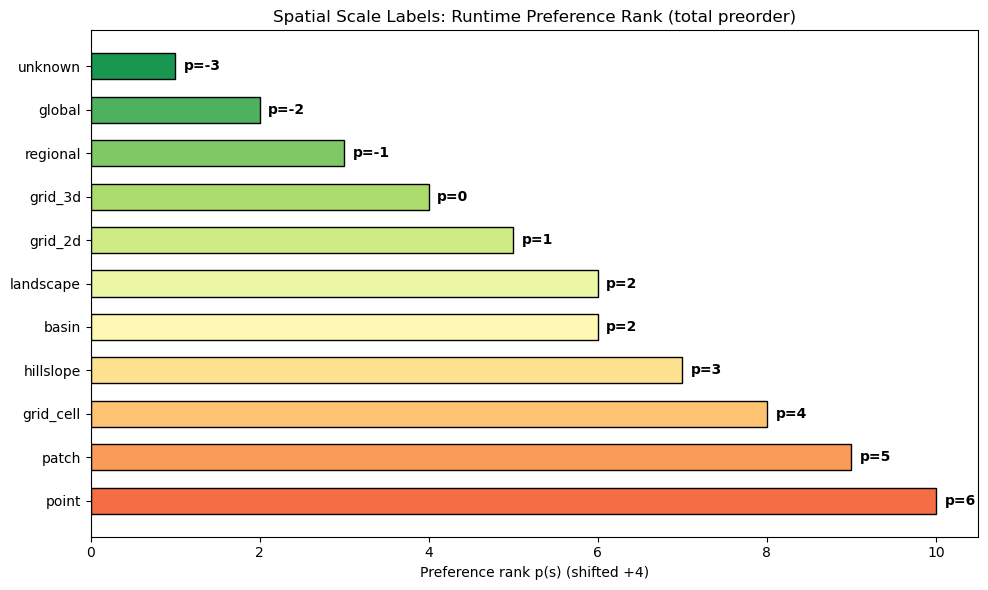

In [9]:
# === Spatial scale labels: runtime preference rank and target-label selection ===
# References:
# - docs/source/theory/spatiotemporal_scale_topology.md, Section 1.1 (Definition 1.1).
# - relic/core/simulator/scale_ops.py (_SCALE_PREFERENCE, _select_target_scale).
# Mathematical expression:
# - s1 <= s2 iff p(s1) >= p(s2) (total preorder on labels)
# - s_target in argmax_{s in U} p(s)
# Parameter meanings:
# - p(s): integer preference rank of label s; U: set of detected labels.
# Units: ranks are dimensionless integers.
# Domain/constraints: basin and landscape share rank 2 (no antisymmetry), so tied maximal ranks
#   leave the returned label unspecified; labels carry no geometry.
# Sign convention: a larger rank is the finer label in the intended containment reading.

import matplotlib.pyplot as plt
import torch
%matplotlib inline
from relic.core.simulator.scale_ops import _SCALE_PREFERENCE, _select_target_scale

label_pairs = [('patch', 'grid_cell'), ('basin', 'regional'), ('point', 'global'), ('hillslope', 'grid_2d')]
print('=== Runtime Preference Ranks (scale_ops._SCALE_PREFERENCE) ===')
ranked_labels = sorted(_SCALE_PREFERENCE.items(), key=lambda item: -item[1])
for label, rank in ranked_labels:
    print('  %-10s p = %d' % (label, rank))

print('\n=== Target Label of a Label Pair (_select_target_scale) ===')
for s1, s2 in label_pairs:
    print('  {%s, %s} -> %s' % (s1, s2, _select_target_scale({s1, s2})))

basin_landscape_tied = _SCALE_PREFERENCE['basin'] == _SCALE_PREFERENCE['landscape']
print('\nbasin and landscape share rank %d: %s (total preorder, not a partial order)'
      % (_SCALE_PREFERENCE['basin'], basin_landscape_tied))
assert basin_landscape_tied

detected_scales = {'patch', 'grid_cell', 'hillslope'}
target = _select_target_scale(detected_scales)
print('Target label for %s: %s' % (sorted(detected_scales), target))
assert target == 'patch'

rank_shift = 1 - min(rank for _, rank in ranked_labels)
fig, ax = plt.subplots(figsize=(10, 6))
color_positions = torch.linspace(0.2, 0.9, len(ranked_labels), dtype=torch.float32)
colors = plt.cm.RdYlGn(color_positions.tolist())
for i, (name, pref) in enumerate(ranked_labels):
    ax.barh(i, pref + rank_shift, color=colors[i], edgecolor='black', height=0.6)
    ax.text(pref + rank_shift + 0.1, i, 'p=%d' % pref, va='center', fontsize=10, fontweight='bold')
ax.set_yticks(range(len(ranked_labels)))
ax.set_yticklabels([label for label, _ in ranked_labels])
ax.set_xlabel('Preference rank p(s) (shifted +%d)' % rank_shift)
ax.set_title('Spatial Scale Labels: Runtime Preference Rank (total preorder)')
plt.tight_layout()
plt.show()


### Temporal Scale Chain & Execution Group Assignment

**Definition 1.2:** The temporal scale chain $\mathcal{T}$ with characteristic time function $\tau$.

**Definition 1.3:** The execution group assignment:

$$
\gamma(t) = \begin{cases}
\text{fast} & \text{if } \tau(t) \le \tau_f \\
\text{medium} & \text{if } \tau_f < \tau(t) \le \tau_m \\
\text{slow} & \text{if } \tau(t) > \tau_m
\end{cases}
$$

The thresholds $\tau_f$ and $\tau_m$ are the parameter-database entries
`computation.scheduling.fast_group_max_characteristic_days` (current configuration value 1 day) and
`computation.scheduling.medium_group_max_characteristic_days` (current configuration value 10 days),
read by `resolve_scheduling_thresholds()`; the code below calls the runtime `determine_execution_group()`,
which uses the same resolver.

This is the characteristic-time branch of the runtime chain: the `register_functor` argument and the
Functor attribute `execution_group` take precedence; `temporal_scale` metadata and `process_groups` come
after, and `fast` applies only when nothing is declared. Every declaration is validated even when a
higher rule decides, and a `process_groups` entry that contradicts the attribute, characteristic-time or
temporal-scale rule raises `ValueError`.
For `TemporalScale`
metadata, SECOND, MINUTE, HOUR, DAY, STATIC and STEADY_STATE use this formula, SUB_DAILY is fast, WEEK
medium, MONTH/SEASON/YEAR slow. The thresholds classify; medium/slow execution times come from
`medium_interval_seconds`, `slow_interval_seconds` or calendar months.


=== Runtime Group of TemporalScale Metadata ===
  second        fast
  minute        fast
  hour          fast
  sub_daily     fast
  day           fast
  week          medium
  month         slow
  season        slow
  year          slow
  static        fast
  steady_state  fast
T_fast   = ['second', 'minute', 'hour', 'sub_daily', 'day', 'static', 'steady_state']
T_medium = ['week']
T_slow   = ['month', 'season', 'year']

=== Runtime Group of characteristic_time_days (tau_f = 1 d, tau_m = 10 d) ===
Realization      tau (days)   gamma    metadata group
------------------------------------------------------
second           1.157e-05    fast     fast
minute           0.0006944    fast     fast
hour             0.04167      fast     fast
day              1            fast     fast
week             7            medium   medium
Jan (noleap)     31           slow     slow
Feb (noleap)     28           slow     slow
month (360_day)  30           slow     slow
year (noleap)    365          sl

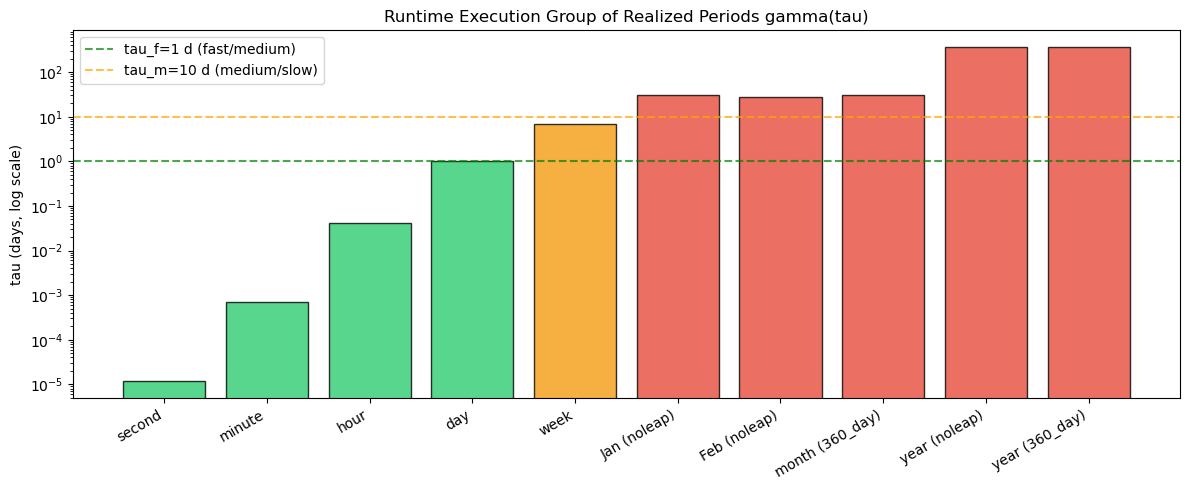

In [10]:
# === Temporal Scale: runtime group assignment and calendar-dependent months ===
# References:
# - docs/source/theory/spatiotemporal_scale_topology.md, Definitions 1.2-1.3 and Section 5.1.
# - relic/core/simulator/dependency_ops.py (determine_execution_group, resolve_scheduling_thresholds).
# - relic/core/simulator/registration.py (_resolve_execution_group: a valid
#   register_functor(execution_group=...) argument precedes the chain probed here).
# - relic/coupling/scales/temporal/calendar.py (CalendarHandler.days_in_month/days_in_year) and
#   relic/coupling/scales/temporal/core.py (PeriodIndexer.elapsed_month_index).
# Mathematical expression:
# - characteristic-time branch: gamma = fast if tau <= tau_f, medium if tau_f < tau <= tau_m, slow otherwise.
# - TemporalScale branch: SECOND, MINUTE, HOUR, DAY, STATIC, STEADY_STATE via tau;
#   SUB_DAILY -> fast; WEEK -> medium; MONTH, SEASON, YEAR -> slow.
# - m_C(t) = zero-based calendar-month index of elapsed time t in calendar C.
# Parameter meanings:
# - tau: characteristic time; tau_f, tau_m: parameter-database thresholds.
# - C: CF calendar type (noleap or 360_day); t: elapsed simulation time.
# Units: tau, tau_f, tau_m and realized periods in days; t in seconds; groups are categorical;
#   month indices are dimensionless integers.
# Domain/constraints: 0 < tau_f < tau_m; UNKNOWN has no mapping and is omitted; the thresholds
#   classify Functors and are not execution intervals; months have no fixed length; every
#   declaration is validated, and an invalid or contradicting one raises ValueError.
# Sign convention: elapsed durations are positive.
from relic.core.simulator.dependency_ops import determine_execution_group, resolve_scheduling_thresholds
from relic.coupling.scales.temporal.core import PeriodIndexer
from relic.parameters import get_global_manager
from relic.utils.time_constants import SECONDS_PER_DAY

TAU_F, TAU_M = resolve_scheduling_thresholds()
# Settings accessor used by the process_groups rule; one probe name is configured there.
CONFIG_VIEW = SimpleNamespace(
    _get_setting=lambda key, default: {'process_groups': {'configured_probe': 'slow'}}.get(key, default)
)


def metadata_probe(name, scale, **attributes):
    return SimpleNamespace(name=name, metadata=SimpleNamespace(temporal_scale=scale), **attributes)


# 1) TemporalScale metadata branch for every declared scale.
scale_groups = {
    scale.value: determine_execution_group(CONFIG_VIEW, metadata_probe(scale.value + '_probe', scale))
    for scale in TemporalScale
    if scale is not TemporalScale.UNKNOWN
}
print('=== Runtime Group of TemporalScale Metadata ===')
for scale_name, group in scale_groups.items():
    print('  %-13s %s' % (scale_name, group))
T_fast = [s for s, g in scale_groups.items() if g == 'fast']
T_medium = [s for s, g in scale_groups.items() if g == 'medium']
T_slow = [s for s, g in scale_groups.items() if g == 'slow']
print('T_fast   =', T_fast)
print('T_medium =', T_medium)
print('T_slow   =', T_slow)

# 2) Characteristic-time branch with fixed SI durations and realized calendar periods.
noleap_handler = CalendarHandler(calendar_type='noleap', time_units='days since 2001-01-01')
day360_handler = CalendarHandler(calendar_type='360_day', time_units='days since 2001-01-01')
realized_periods = [
    ('second', 'second', TemporalScale.SECOND.to_characteristic_time_days()),
    ('minute', 'minute', TemporalScale.MINUTE.to_characteristic_time_days()),
    ('hour', 'hour', TemporalScale.HOUR.to_characteristic_time_days()),
    ('day', 'day', TemporalScale.DAY.to_characteristic_time_days()),
    ('week', 'week', TemporalScale.WEEK.to_characteristic_time_days(period_days=7.0)),
    ('Jan (noleap)', 'month', float(noleap_handler.days_in_month(1, 2001))),
    ('Feb (noleap)', 'month', float(noleap_handler.days_in_month(2, 2001))),
    ('month (360_day)', 'month', float(day360_handler.days_in_month(2, 2001))),
    ('year (noleap)', 'year', float(noleap_handler.days_in_year(2001))),
    ('year (360_day)', 'year', float(day360_handler.days_in_year(2001))),
]
print('\n=== Runtime Group of characteristic_time_days (tau_f = %g d, tau_m = %g d) ===' % (TAU_F, TAU_M))
print('%-16s %-12s %-8s %s' % ('Realization', 'tau (days)', 'gamma', 'metadata group'))
print('-' * 54)
realized_groups = []
for label, scale_name, tau_days in realized_periods:
    group = determine_execution_group(
        CONFIG_VIEW, SimpleNamespace(name=label, characteristic_time_days=tau_days)
    )
    realized_groups.append(group)
    print('%-16s %-12.4g %-8s %s' % (label, tau_days, group, scale_groups[scale_name]))
    assert group == scale_groups[scale_name]

# 3) Priority chain: attribute > characteristic_time_days > temporal_scale > process_groups >
#    fast (only when nothing is declared).
priority_probes = {
    'attribute slow over HOUR': metadata_probe('attribute_probe', TemporalScale.HOUR, execution_group='slow'),
    'tau 5 d over YEAR': metadata_probe('tau_probe', TemporalScale.YEAR, characteristic_time_days=5.0),
    'MONTH metadata only': metadata_probe('month_probe', TemporalScale.MONTH),
    'process_groups entry': metadata_probe('configured_probe', TemporalScale.UNKNOWN),
    'nothing declared': SimpleNamespace(name='bare_probe'),
}
priority_groups = {label: determine_execution_group(CONFIG_VIEW, probe) for label, probe in priority_probes.items()}
print('\n=== Priority Chain (determine_execution_group) ===')
for label, group in priority_groups.items():
    print('  %-26s -> %s' % (label, group))
assert priority_groups == {
    'attribute slow over HOUR': 'slow',
    'tau 5 d over YEAR': 'medium',
    'MONTH metadata only': 'slow',
    'process_groups entry': 'slow',
    'nothing declared': 'fast',
}

# 4) Every declaration is validated, also when a higher rule decides; there are no aliases.
rejected_declarations = {
    'process_groups slow vs HOUR metadata': metadata_probe('configured_probe', TemporalScale.HOUR),
    'tau -1 d under attribute fast': metadata_probe(
        'negative_tau_probe', TemporalScale.UNKNOWN, execution_group='fast', characteristic_time_days=-1.0
    ),
    "temporal_scale 'daily'": metadata_probe('alias_probe', 'daily'),
}
print('\n=== Rejected Declarations (determine_execution_group raises ValueError) ===')
for label, probe in rejected_declarations.items():
    try:
        determine_execution_group(CONFIG_VIEW, probe)
    except ValueError as exc:
        print('  %-38s -> %s' % (label, str(exc).split(';')[0]))
    else:
        raise AssertionError('%s was accepted' % label)
try:
    SpatialScale.from_value('grid2d')
except ValueError as exc:
    print('  SpatialScale.from_value("grid2d") -> ValueError: %s' % str(exc).split(';')[0])
else:
    raise AssertionError("The retired grid2d alias must be rejected")
assert SpatialScale.from_value('grid_2d') is SpatialScale.GRID_2D
print('  SpatialScale.from_value("grid_2d") -> %s' % SpatialScale.GRID_2D)

# 5) Slow-trigger month boundaries follow the configured calendar (no fixed 30-day month).
period_indexer = PeriodIndexer(device=torch.device('cpu'), parameter_manager=get_global_manager())
month_index = {
    calendar_name: {
        day: period_indexer.elapsed_month_index(day * float(SECONDS_PER_DAY), calendar_name)
        for day in (30.0, 31.0)
    }
    for calendar_name in ('noleap', '360_day')
}
print('\n=== Calendar Month Index m_C(t) ===')
for calendar_name, indices in month_index.items():
    print('  %-8s t = 30 d -> %d, t = 31 d -> %d' % (calendar_name, indices[30.0], indices[31.0]))
assert month_index['noleap'] == {30.0: 0, 31.0: 1}
assert month_index['360_day'] == {30.0: 1, 31.0: 1}

fig, ax = plt.subplots(figsize=(12, 5))
group_colors = {'fast': '#2ecc71', 'medium': '#f39c12', 'slow': '#e74c3c'}
plotted = [(label, tau_days) for label, _, tau_days in realized_periods]
ax.bar(range(len(plotted)), [tau for _, tau in plotted],
       color=[group_colors[g] for g in realized_groups], edgecolor='black', alpha=0.8)
ax.set_yscale('log')
ax.set_xticks(range(len(plotted)))
ax.set_xticklabels([label for label, _ in plotted], rotation=30, ha='right')
ax.set_ylabel('tau (days, log scale)')
ax.set_title('Runtime Execution Group of Realized Periods gamma(tau)')
ax.axhline(TAU_F, color='green', ls='--', alpha=0.7, label='tau_f=%g d (fast/medium)' % TAU_F)
ax.axhline(TAU_M, color='orange', ls='--', alpha=0.7, label='tau_m=%g d (medium/slow)' % TAU_M)
ax.legend()
plt.tight_layout()
plt.show()


The tables above come from the runtime. Fixed SI scales resolve $\tau$ from the time-constant SSOT;
`sub_daily`, `week`, `month`, `season` and `year` are calendar- or schedule-dependent and map directly to
fast, medium, slow, slow and slow, and every supported realization stays inside that class.
`TemporalScale.MONTH` has no fixed length: a realized month is 31 days (January) or 28 days (February) in
`noleap` and 30 days in `360_day`, and the slow trigger follows the calendar-month boundaries of the
configured calendar unless `slow_interval_seconds` is set. The thresholds $\tau_f, \tau_m$ classify
Functors; they are not execution intervals. The rejected declarations show the validation: a
`process_groups` entry that contradicts the temporal-scale rule, a negative `characteristic_time_days`
under a valid attribute, and the former alias `daily` each raise `ValueError`; `SpatialScale.from_value`
likewise rejects `grid2d` and accepts only the member value `grid_2d`.

## Summary

This notebook demonstrated the spatiotemporal scale topology:
- Spatial scale labels with the runtime preference rank (a total preorder) and target-label selection
- Fast/medium/slow group assignment through the runtime priority chain (every declaration validated,
  `fast` only when nothing is declared), and calendar-dependent months
- Execution bands from parameter-database thresholds and pure interval predicates with explicit commit
- Functor-level `VariableKind` role labels (no INCREMENT kind)

**Next:** Proceed to **NB07** for extensions, monitoring, and utility APIs.